# 📊 ForexMiner
Análisis Exploratorio de Datos

## Preliminares

In [1]:
import pandas as pd

# Mover el working directory a la raiz
import os; os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None

from src.modeling import cargar_datos_clean, wide_to_long_panel
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo,
    rankear_variables, categorizar_por_cuantiles
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 905 entries, 2008-06-30 to 2026-11-23
Columns: 154 entries, EUR_Ret_std_zscore_lag1 to USD_Ret_rank_lag1
dtypes: float64(154)
memory usage: 1.1 MB


/home/sebas/miniconda3/envs/ml313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Análisis de variables transformadas

In [5]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "Ret_vol_dir_zscore_exposure_lag1"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EUR_Gold_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.006274,0.197563,-1.493895,-0.074519,-0.005146,0.053642,0.825751
EUR_Oil_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.014952,0.246725,-1.809513,-0.099239,-0.006163,0.076901,1.430634
EUR_SPY_Ret_vol_dir_zscore_exposure_lag1,905.0,0.010792,0.194484,-1.040020,-0.070569,-0.004848,0.066521,1.760860
GBP_Gold_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.005815,0.197650,-1.311511,-0.081902,-0.005415,0.062855,1.312112
GBP_Oil_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.016909,0.206015,-1.103762,-0.085524,-0.000051,0.076525,0.803943
GBP_SPY_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.047964,0.204416,-1.094809,-0.130007,-0.006203,0.060057,0.767611
AUD_Gold_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.016560,0.189627,-0.703518,-0.095406,-0.008384,0.048364,0.984445
AUD_Oil_Ret_vol_dir_zscore_exposure_lag1,905.0,-0.012686,0.255654,-1.717222,-0.075184,0.001973,0.073774,1.282264
AUD_SPY_Ret_vol_dir_zscore_exposure_lag1,905.0,0.008397,0.275549,-1.472234,-0.090970,0.022788,0.162849,1.281477
JPY_Gold_Ret_vol_dir_zscore_exposure_lag1,905.0,0.018159,0.203025,-0.916549,-0.048442,0.004877,0.088225,0.984246


In [6]:
# Asimetrias general
mostrar_asimetrias(df_clean)

EUR_SPY_Ret_vol_dir_zscore_exposure_lag1        2.464006
JPY_SPY_Ret_vol_dir_zscore_exposure_lag1        1.521868
CHF_Gold_Ret_std_zscore_exposure_lag1           1.387167
CHF_VIX_accel26w_lag1_zscore_exposure           1.340485
EUR_Gold_Ret_std_zscore_exposure_lag1           1.279151
USD_Oil_Ret_vol_dir_zscore_exposure_lag1        1.239489
CHF_Gold_Ret_vol_dir_zscore_exposure_lag1       1.157326
CHF_SPY_Ret_vol_dir_zscore_exposure_lag1        1.155916
JPY_Oil_Ret_vol_dir_zscore_exposure_lag1        1.145791
JPY_Oil_Ret_std_zscore_exposure_lag1            0.957217
USD_Oil_Ret_std_zscore_exposure_lag1            0.858393
EUR_STLFSI_accel26w_lag1_zscore_exposure        0.848582
JPY_T10Y2Y_delta_lag1_zscore_exposure           0.841322
USD_Gold_Ret_std_zscore_exposure_lag1           0.789363
USD_VIX_accel26w_lag1_zscore_exposure           0.787248
JPY_Oil_Ret_zscore_exposure_lag1                0.770242
USD_T10Y2Y_accel26w_lag1_zscore_exposure        0.766607
EUR_SPY_Ret_std_zscore_exposure

In [7]:
# Asimetria por grupo
cadena = "CAD_Ret_std_zscore_lag1"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

CAD_Ret_std_zscore_lag1    0.241393


Cont


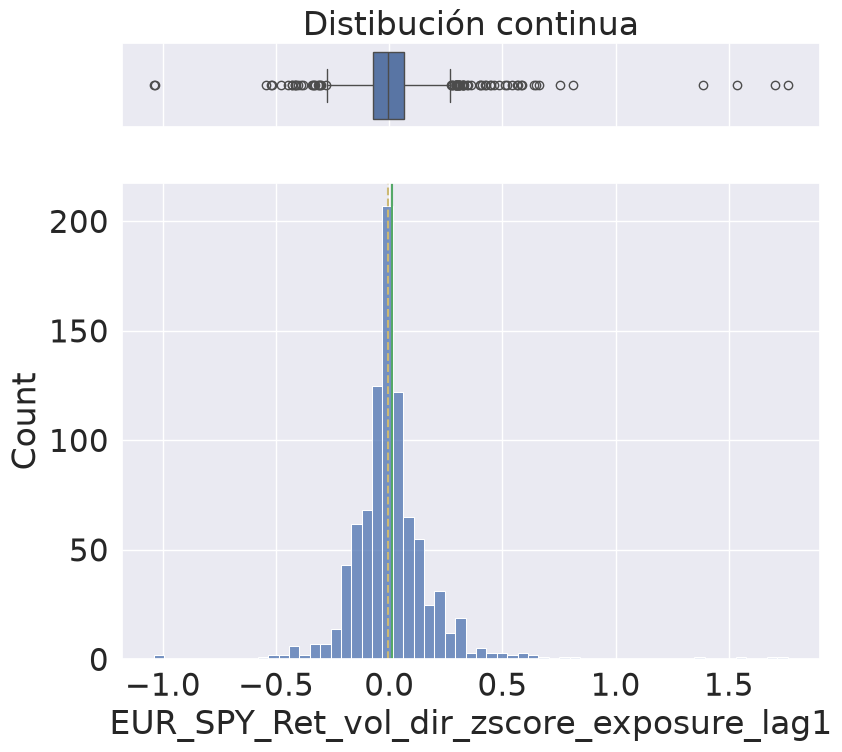

In [8]:
# Visualizar columna
col = 'EUR_SPY_Ret_vol_dir_zscore_exposure_lag1'
pintar_columna(df_clean[col])

## Análisis de datos de panel

In [9]:
# Convertir a formato largo
df_long = wide_to_long_panel(df_clean)

df_panel = df_long.set_index(["date", "Currency"])

df_panel.info()

<class 'pandas.DataFrame'>
MultiIndex: 6335 entries, (Timestamp('2008-06-30 00:00:00'), 'AUD') to (Timestamp('2026-11-23 00:00:00'), 'USD')
Data columns (total 22 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Target_rank                               6335 non-null   float64
 1   Ret_std_zscore_lag1                       6335 non-null   float64
 2   Ret_vol_dir_zscore_lag1                   6335 non-null   float64
 3   Ret_accel_zscore_lag1                     6335 non-null   float64
 4   Gold_Ret_zscore_exposure_lag1             6335 non-null   float64
 5   Gold_Ret_std_zscore_exposure_lag1         6335 non-null   float64
 6   Gold_Ret_vol_dir_zscore_exposure_lag1     6335 non-null   float64
 7   Oil_Ret_zscore_exposure_lag1              6335 non-null   float64
 8   Oil_Ret_std_zscore_exposure_lag1          6335 non-null   float64
 9   Oil_Ret_vol_dir_zscore_exposure_lag1     

In [10]:
# Tabla de Correlaciones general
top_correlaciones(df=df_panel, top_n=30)

,Variable A,Variable B,correlation
43,Oil_Ret_vol_dir_zscore_exposure_lag1,Oil_Ret_zscore_exposure_lag1,0.396406
76,SPY_Ret_vol_dir_zscore_exposure_lag1,SPY_Ret_zscore_exposure_lag1,0.368105
75,SPY_Ret_vol_dir_zscore_exposure_lag1,Oil_Ret_vol_dir_zscore_exposure_lag1,0.362891
38,Oil_Ret_vol_dir_zscore_exposure_lag1,Ret_vol_dir_zscore_lag1,0.338515
213,Ret_rank_lag1,Ret_accel_zscore_lag1,0.335548
212,Ret_rank_lag1,Ret_vol_dir_zscore_lag1,0.333772
206,T10Y2Y_accel26w_lag1_zscore_exposure,Real_yield_accel26w_lag1_zscore_exposure,0.330738
17,Gold_Ret_vol_dir_zscore_exposure_lag1,Ret_vol_dir_zscore_lag1,0.325836
68,SPY_Ret_vol_dir_zscore_exposure_lag1,Ret_vol_dir_zscore_lag1,0.321656
220,Ret_rank_lag1,SPY_Ret_zscore_exposure_lag1,0.317430


### Correlación de predictores con la variable objetivo

In [11]:
col_objetivo = "Target_rank"
y = df_panel[col_objetivo].astype('category')
X = df_panel.drop(columns=col_objetivo)

top_correlaciones_objetivo(df=X, target_series=y)

,Variable,Correlación
0,Real_yield_delta_lag1_zscore_exposure,0.187100
1,T10Y2Y_delta_lag1_zscore_exposure,0.178334
2,VIX_pct_diff_lag1_zscore_exposure,0.174243
3,STLFSI_delta_lag1_zscore_exposure,0.172791
4,Real_yield_accel26w_lag1_zscore_exposure,0.169067
5,T10Y2Y_accel26w_lag1_zscore_exposure,0.162283
6,VIX_accel26w_lag1_zscore_exposure,0.155619
7,STLFSI_accel26w_lag1_zscore_exposure,0.140492
8,Gold_Ret_vol_dir_zscore_exposure_lag1,-0.044943
9,Ret_rank_lag1,-0.039468


In [12]:
# Verificar frecuencia de clases
y.value_counts()

Target_rank
0.000000    905
0.166667    904
1.000000    904
0.500000    903
0.666667    903
0.333333    902
0.833333    902
0.416667      4
0.750000      4
0.250000      2
0.916667      2
Name: count, dtype: int64

** Valores de baja frecuencia: empates en el ranking

### Ranking de variables (V de Cramer)

In [13]:
_ = rankear_variables(X=X, y=y, percentil=50, graficar=True)

### Gráficos de violines

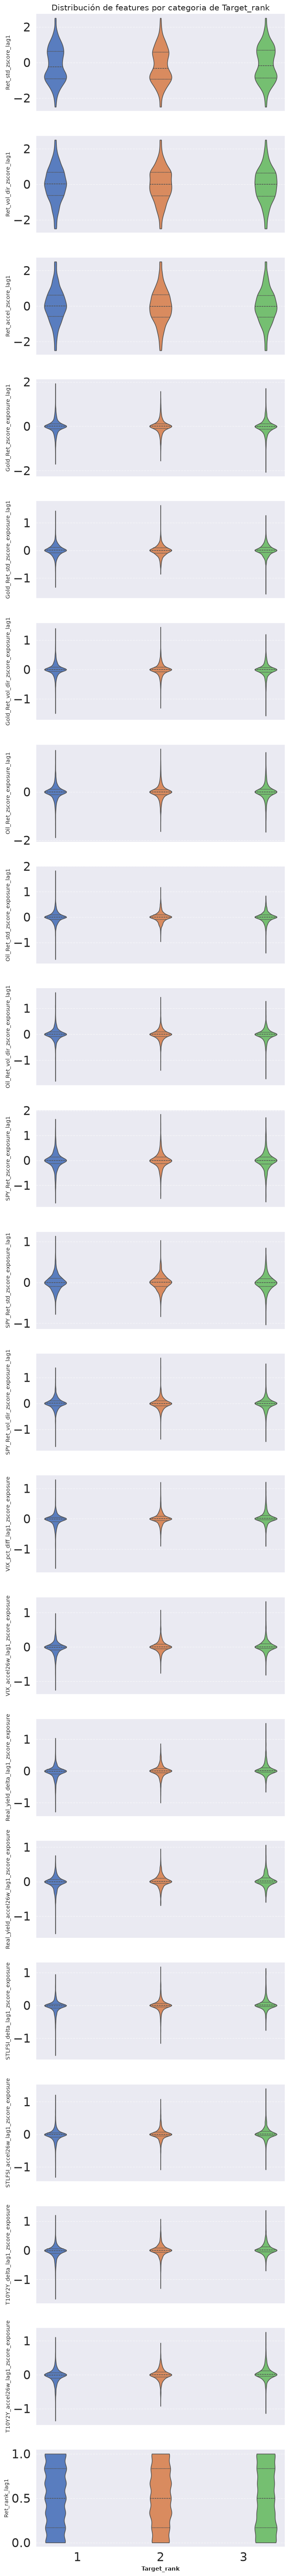

In [14]:
# Violin plot
# Para facilitar la visualizacion, se agrupa la variable objetivo en 3 cuantiles
y_cat = categorizar_por_cuantiles(serie=y)

# Identificar las variables numéricas excluyendo la variable objetivo
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

# Filtrar predictores
cadena = ""
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

df_merged = pd.concat([X[columnas], y_cat], axis=1)

pintar_violin_plots(
    df=df_merged,
    numeric_cols=columnas,
    target_col=col_objetivo
)